custom_df columns: ['Image Data ID', 'Subject', 'Group', 'Sex', 'Age', 'Visit', 'Modality', 'Description', 'Type', 'Acq Date', 'Format', 'Downloaded']
manifest_df columns: ['Subject', 'RID', 'ImageID', 'DateDir', 'SeriesPath', 'SlicesCount', 'VolumeNiftiBiasCorr', 'VolumeNiftiStd']
Class counts:
AD       406
CN       951
EMCI    1120
LMCI     576
MCI      459
SMC      143
Name: count, dtype: int64


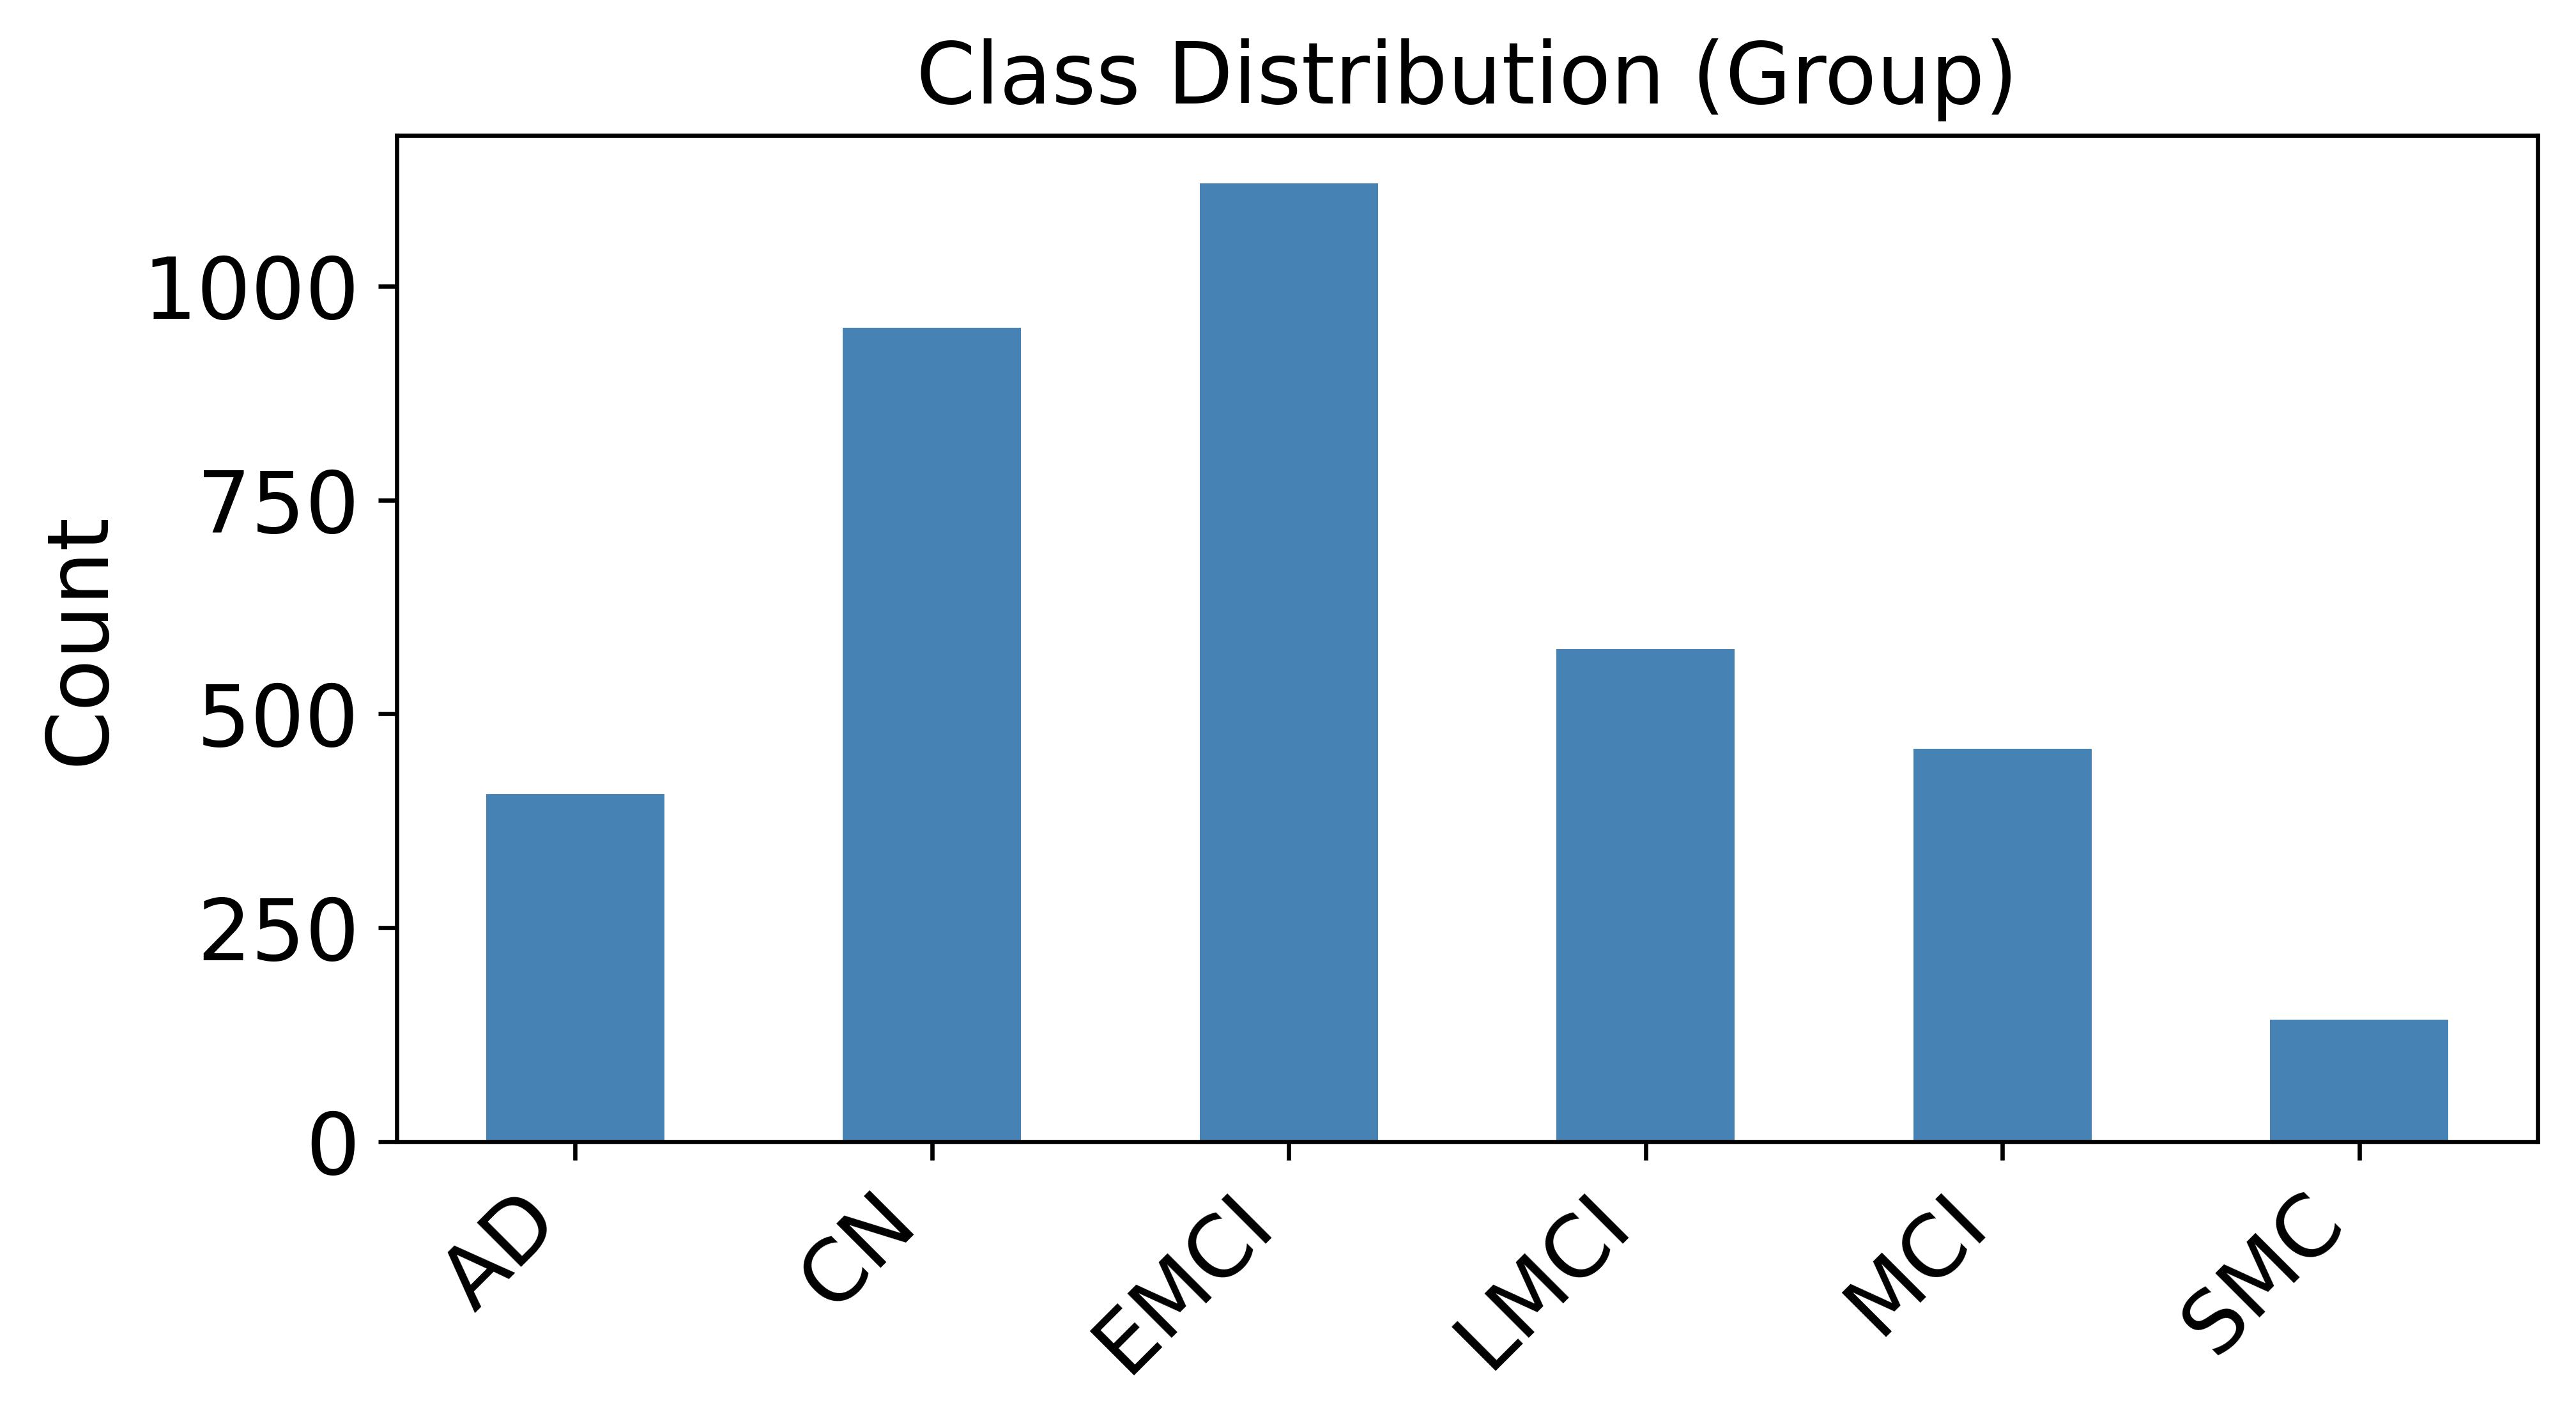

In [17]:
# Class distribution bar plot (prints columns first)
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
DPI = 600
TITLE_SIZE = 16
LABEL_SIZE = 16
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)
BASE = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/")
PROJECT_ROOT = BASE / "Projects/MutimodelFutureTrends"
CUSTOM_CSV = PROJECT_ROOT / "CstomIds_MPRAGE_9_30_2025.csv"
MANIFEST_CSV = PROJECT_ROOT / "manifests/mri_manifest_biascorr.csv"
custom_df = pd.read_csv(CUSTOM_CSV)
manifest_df = pd.read_csv(MANIFEST_CSV)
print("custom_df columns:", list(custom_df.columns))
print("manifest_df columns:", list(manifest_df.columns))
custom_df.rename(columns={"Image Data ID": "ImageID"}, inplace=True)
custom_df["ImageID"] = custom_df["ImageID"].astype(str).str.strip()
def pick_label_col(df):
    for col in df.columns:
        if col.lower() == "group":
            return col
    for col in df.columns:
        if "group" in col.lower():
            return col
    return None
label_col = pick_label_col(custom_df)
if label_col is None:
    raise KeyError("No column containing 'Group' found in custom_df")
merged = custom_df[["ImageID", label_col]].copy()
merged[label_col] = merged[label_col].astype('category')
class_order = merged[label_col].cat.categories
counts = merged[label_col].value_counts().reindex(class_order)
print("Class counts:")
print(counts)
plt.rcParams.update({"font.size": LABEL_SIZE})
plt.figure(figsize=(7, 4), dpi=DPI)
counts.plot(kind="bar", color="steelblue")
plt.ylabel("Count", fontsize=LABEL_SIZE)
plt.title(f"Class Distribution ({label_col})", fontsize=TITLE_SIZE)
plt.xticks(rotation=45, ha="right", fontsize=LABEL_SIZE)
plt.yticks(fontsize=LABEL_SIZE)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "class_distribution.jpg", dpi=DPI, bbox_inches="tight")
plt.show()


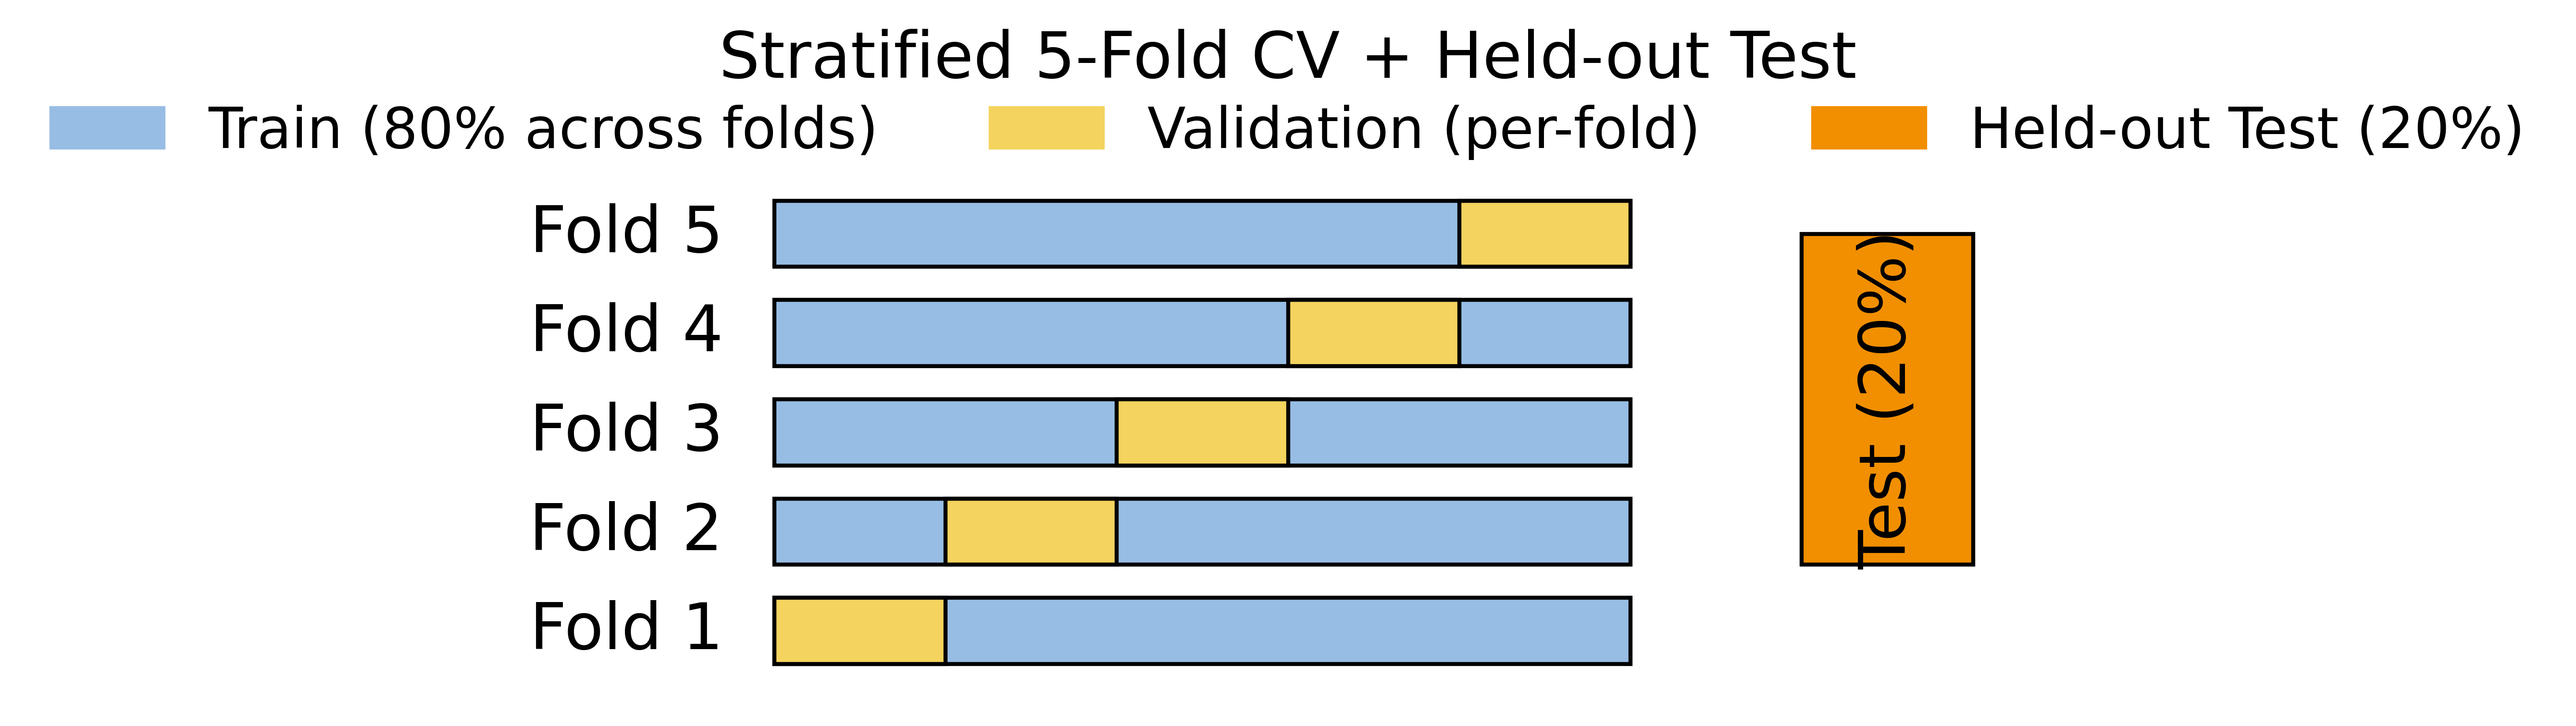

In [18]:
# Cross-validation schematic (5 folds + held-out test, with legend)
import matplotlib.pyplot as plt
import matplotlib.patches as patches
DPI = 600
TITLE_SIZE = 16
LABEL_SIZE = 16
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)
folds = 5
train_color = "#97bde4"  # light gray
val_color = "#f4d35e"    # amber
test_color = "#f18f01"   # orange
fig, ax = plt.subplots(figsize=(8, 2.8), dpi=DPI)
y0 = 0
for i in range(folds):
    y = y0 + i * 0.6
    ax.add_patch(patches.Rectangle((0, y), 5, 0.4, edgecolor="k", facecolor=train_color, lw=1))
    ax.add_patch(patches.Rectangle((i, y), 1, 0.4, edgecolor="k", facecolor=val_color, lw=1))
    ax.text(-0.3, y+0.2, f"Fold {i+1}", ha="right", va="center", fontsize=LABEL_SIZE)
ax.add_patch(patches.Rectangle((6, 0.6), 1, 0.4*folds, edgecolor="k", facecolor=test_color, lw=1))
ax.text(6.5, 0.6+0.2*folds, "Test (20%)", ha="center", va="center", rotation=90, fontsize=LABEL_SIZE)
legend_handles = [
    patches.Patch(color=train_color, label="Train (80% across folds)"),
    patches.Patch(color=val_color, label="Validation (per-fold)"),
    patches.Patch(color=test_color, label="Held-out Test (20%)"),
]
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.08), ncol=3, fontsize=LABEL_SIZE-2, frameon=False)
ax.set_xlim(-1.2, 7.2)
ax.set_ylim(-0.2, folds*0.6+0.4)
ax.axis("off")
ax.set_title("Stratified 5-Fold CV + Held-out Test", fontsize=TITLE_SIZE)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "stratified_5fold_cv.jpg", dpi=DPI, bbox_inches="tight")
plt.show()


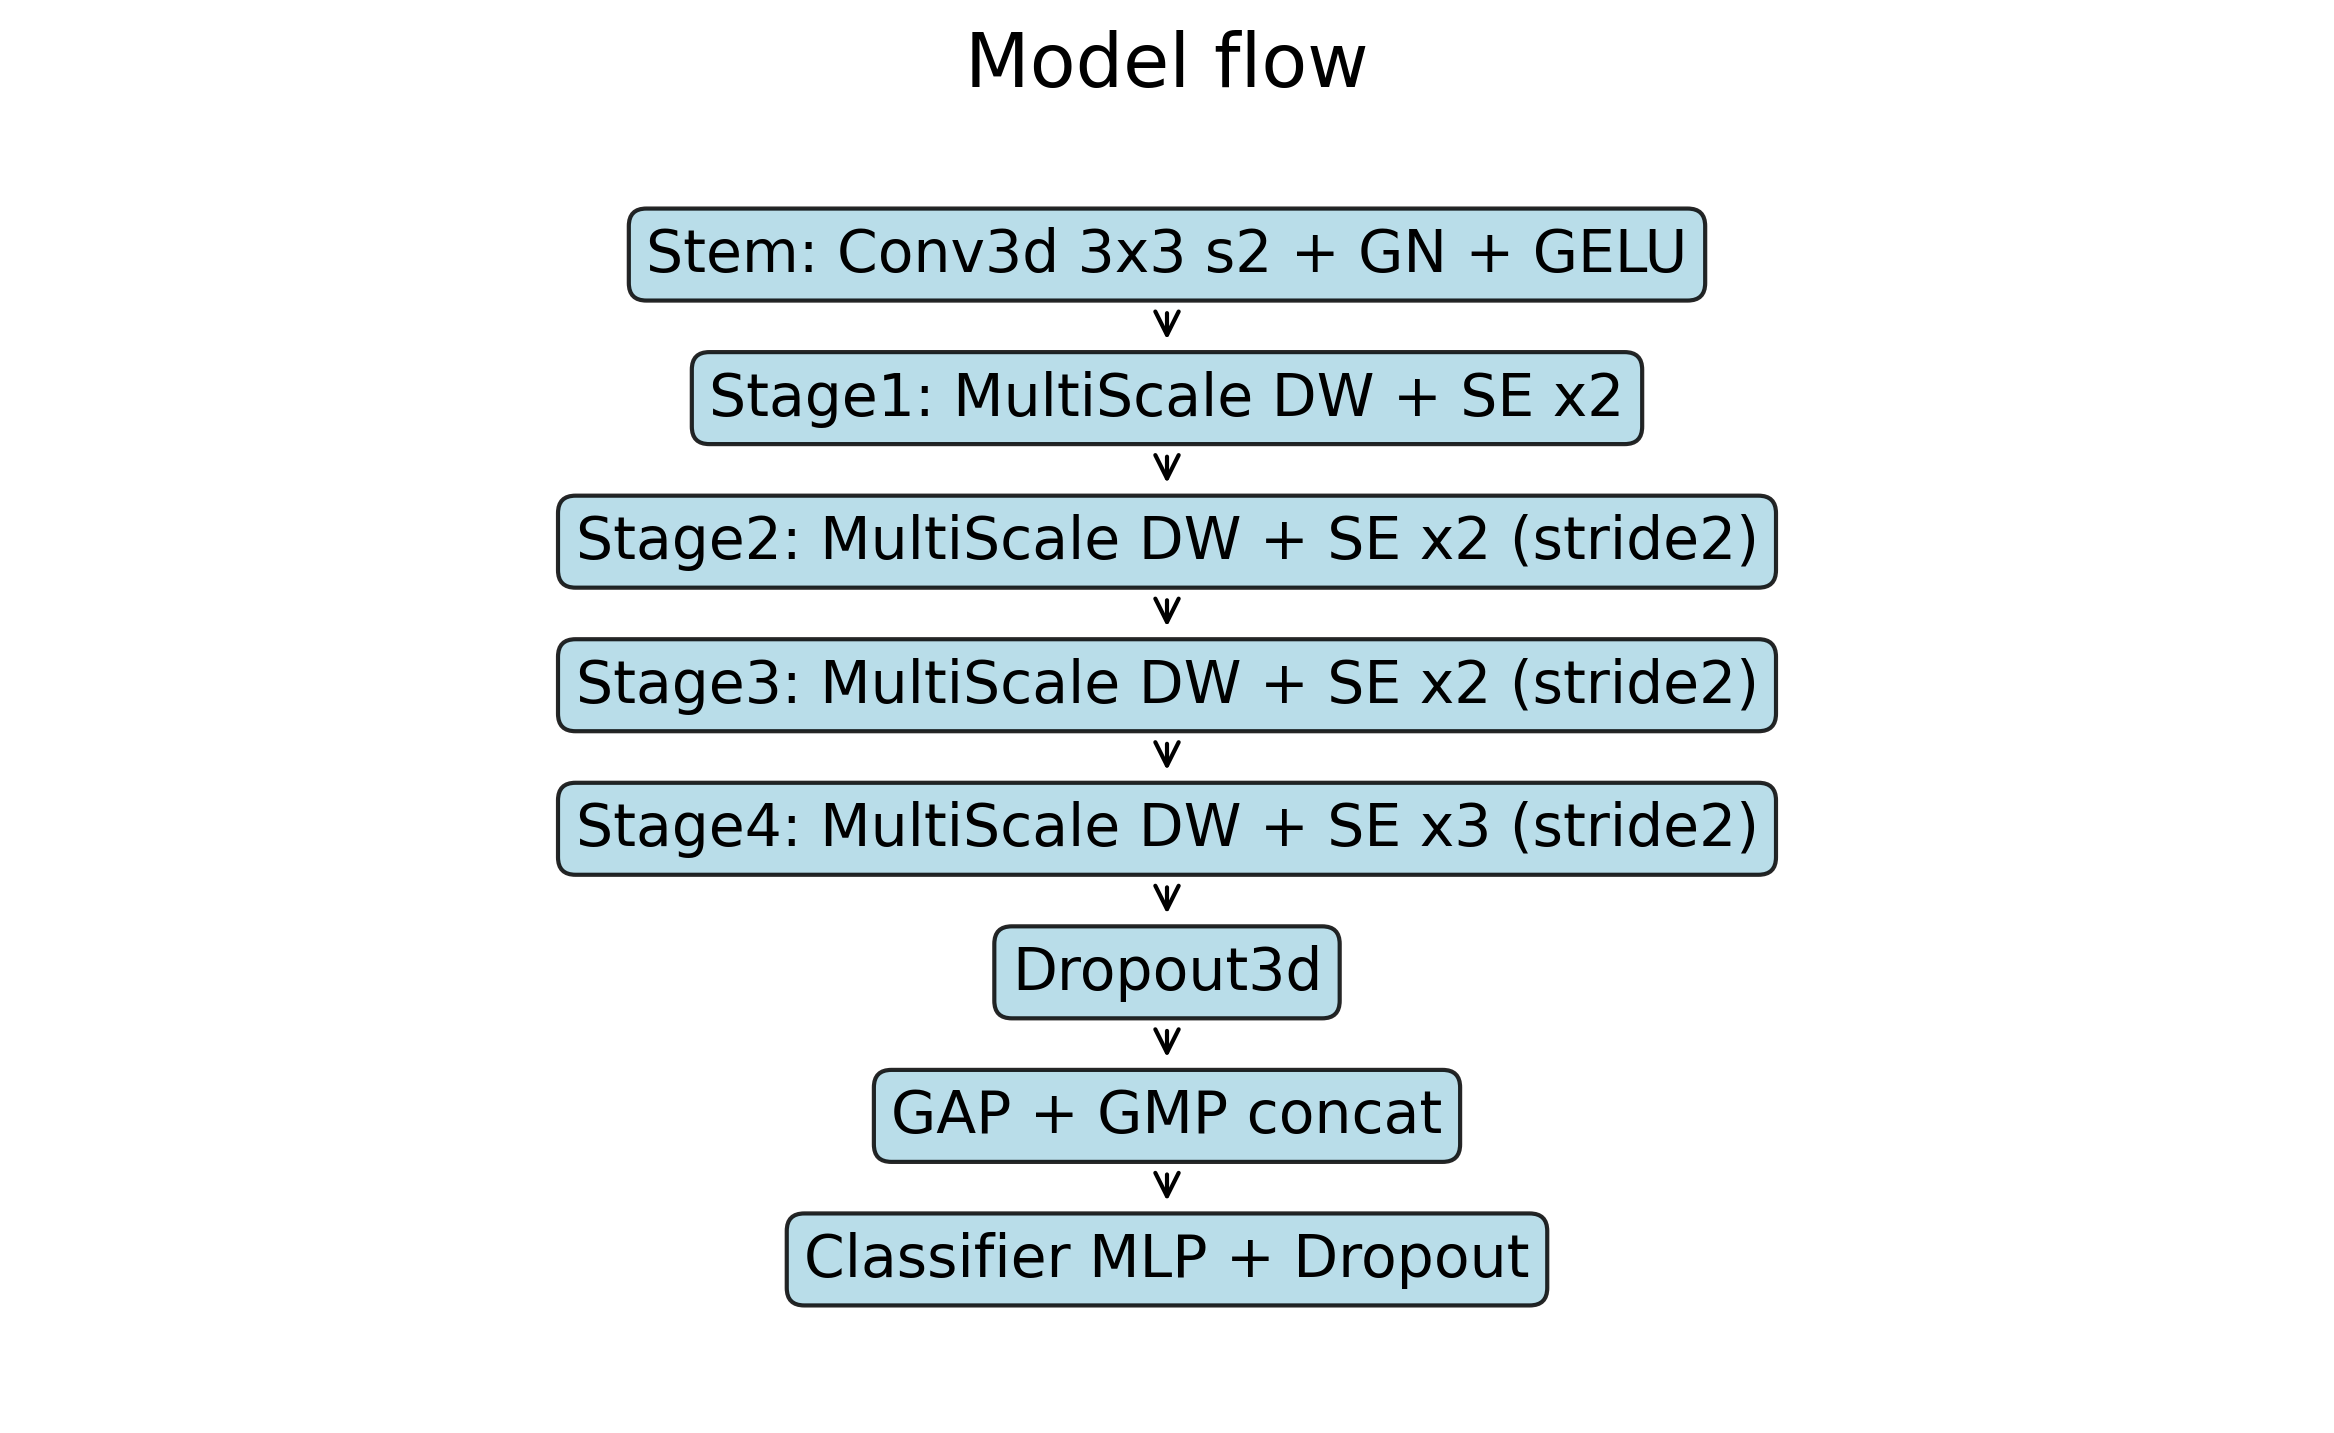

In [7]:
# Architecture sketch: BetterEfficient3DEncoder (block sequence)
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
DPI = 600
TITLE_SIZE = 16
LABEL_SIZE = 16
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)
blocks = [
    ("Stem: Conv3d 3x3 s2 + GN + GELU", 0),
    ("Stage1: MultiScale DW + SE x2", -1),
    ("Stage2: MultiScale DW + SE x2 (stride2)", -2),
    ("Stage3: MultiScale DW + SE x2 (stride2)", -3),
    ("Stage4: MultiScale DW + SE x3 (stride2)", -4),
    ("Dropout3d", -5),
    ("GAP + GMP concat", -6),
    ("Classifier MLP + Dropout", -7),
]
fig, ax = plt.subplots(figsize=(8, 5), dpi=DPI)
for i, (label, y) in enumerate(blocks):
    ax.text(0, y, label, bbox=dict(boxstyle="round", facecolor="lightblue", alpha=0.85), fontsize=LABEL_SIZE, ha="center", va="center")
    if i < len(blocks)-1:
        arr = FancyArrowPatch((0, y-0.35), (0, blocks[i+1][1]+0.35), arrowstyle='->', mutation_scale=14)
        ax.add_patch(arr)
ax.set_xlim(-1, 1)
ax.set_ylim(-8, 1)
ax.axis("off")
ax.set_title("Model flow", fontsize=TITLE_SIZE)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "architecture_flow.png", dpi=DPI, bbox_inches="tight")
plt.show()


In [19]:
# Demographic statistics by class (n, mean age, std age, % female, % male)
import pandas as pd
from pathlib import Path

BASE = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/")
PROJECT_ROOT = BASE / "Projects/MutimodelFutureTrends"
CUSTOM_CSV = PROJECT_ROOT / "CstomIds_MPRAGE_9_30_2025.csv"

custom_df = pd.read_csv(CUSTOM_CSV)
custom_df.rename(columns={"Image Data ID": "ImageID"}, inplace=True)
custom_df["ImageID"] = custom_df["ImageID"].astype(str).str.strip()

def pick_col(df, keywords):
    cols = [c for c in df.columns if c.lower() in keywords]
    if cols:
        return cols[0]
    for c in df.columns:
        cl = c.lower()
        for kw in keywords:
            if kw in cl:
                return c
    return None

label_col = pick_col(custom_df, {"group"})
age_col   = pick_col(custom_df, {"age"})
sex_col   = pick_col(custom_df, {"sex", "gender"})

if label_col is None:
    raise KeyError("No class/group column found (looked for 'group')")

df = custom_df.copy()
df[label_col] = df[label_col].astype('category')

def norm_sex(x):
    s = str(x).strip().lower()
    if s in {"f", "female", "woman", "women"} or s.startswith('f'):
        return 'F'
    if s in {"m", "male", "man", "men"} or s.startswith('m'):
        return 'M'
    return None

rows = []
for cls, g in df.groupby(label_col):
    n = len(g)
    mean_age = std_age = None
    pct_f = pct_m = None
    if age_col is not None:
        ages = pd.to_numeric(g[age_col], errors='coerce').dropna()
        if len(ages):
            mean_age = ages.mean()
            std_age = ages.std()
    if sex_col is not None:
        sex_norm = g[sex_col].map(norm_sex)
        total_sex = sex_norm.notna().sum()
        if total_sex > 0:
            pct_f = 100 * (sex_norm == 'F').sum() / total_sex
            pct_m = 100 * (sex_norm == 'M').sum() / total_sex
    rows.append({
        label_col: cls,
        'n': n,
        'mean_age': None if mean_age is None else round(mean_age, 2),
        'std_age': None if std_age is None else round(std_age, 2),
        'pct_female': None if pct_f is None else round(pct_f, 2),
        'pct_male': None if pct_m is None else round(pct_m, 2),
    })

stats_df = pd.DataFrame(rows)
print(f"Label column: {label_col}")
print(f"Age column: {age_col}")
print(f"Sex column: {sex_col}")
display(stats_df)


Label column: Group
Age column: Age
Sex column: Sex


/tmp/ipykernel_3807906/1672900641.py:43: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for cls, g in df.groupby(label_col):


,Group,n,mean_age,std_age,pct_female,pct_male
0,AD,406,75.38,7.81,45.32,54.68
1,CN,951,75.39,6.67,51.10,48.90
2,EMCI,1120,71.89,7.10,43.84,56.16
3,LMCI,576,72.65,8.40,52.70,47.30
4,MCI,459,74.13,7.80,41.18,58.82
5,SMC,143,73.05,5.60,55.24,44.76


PREprocessing information

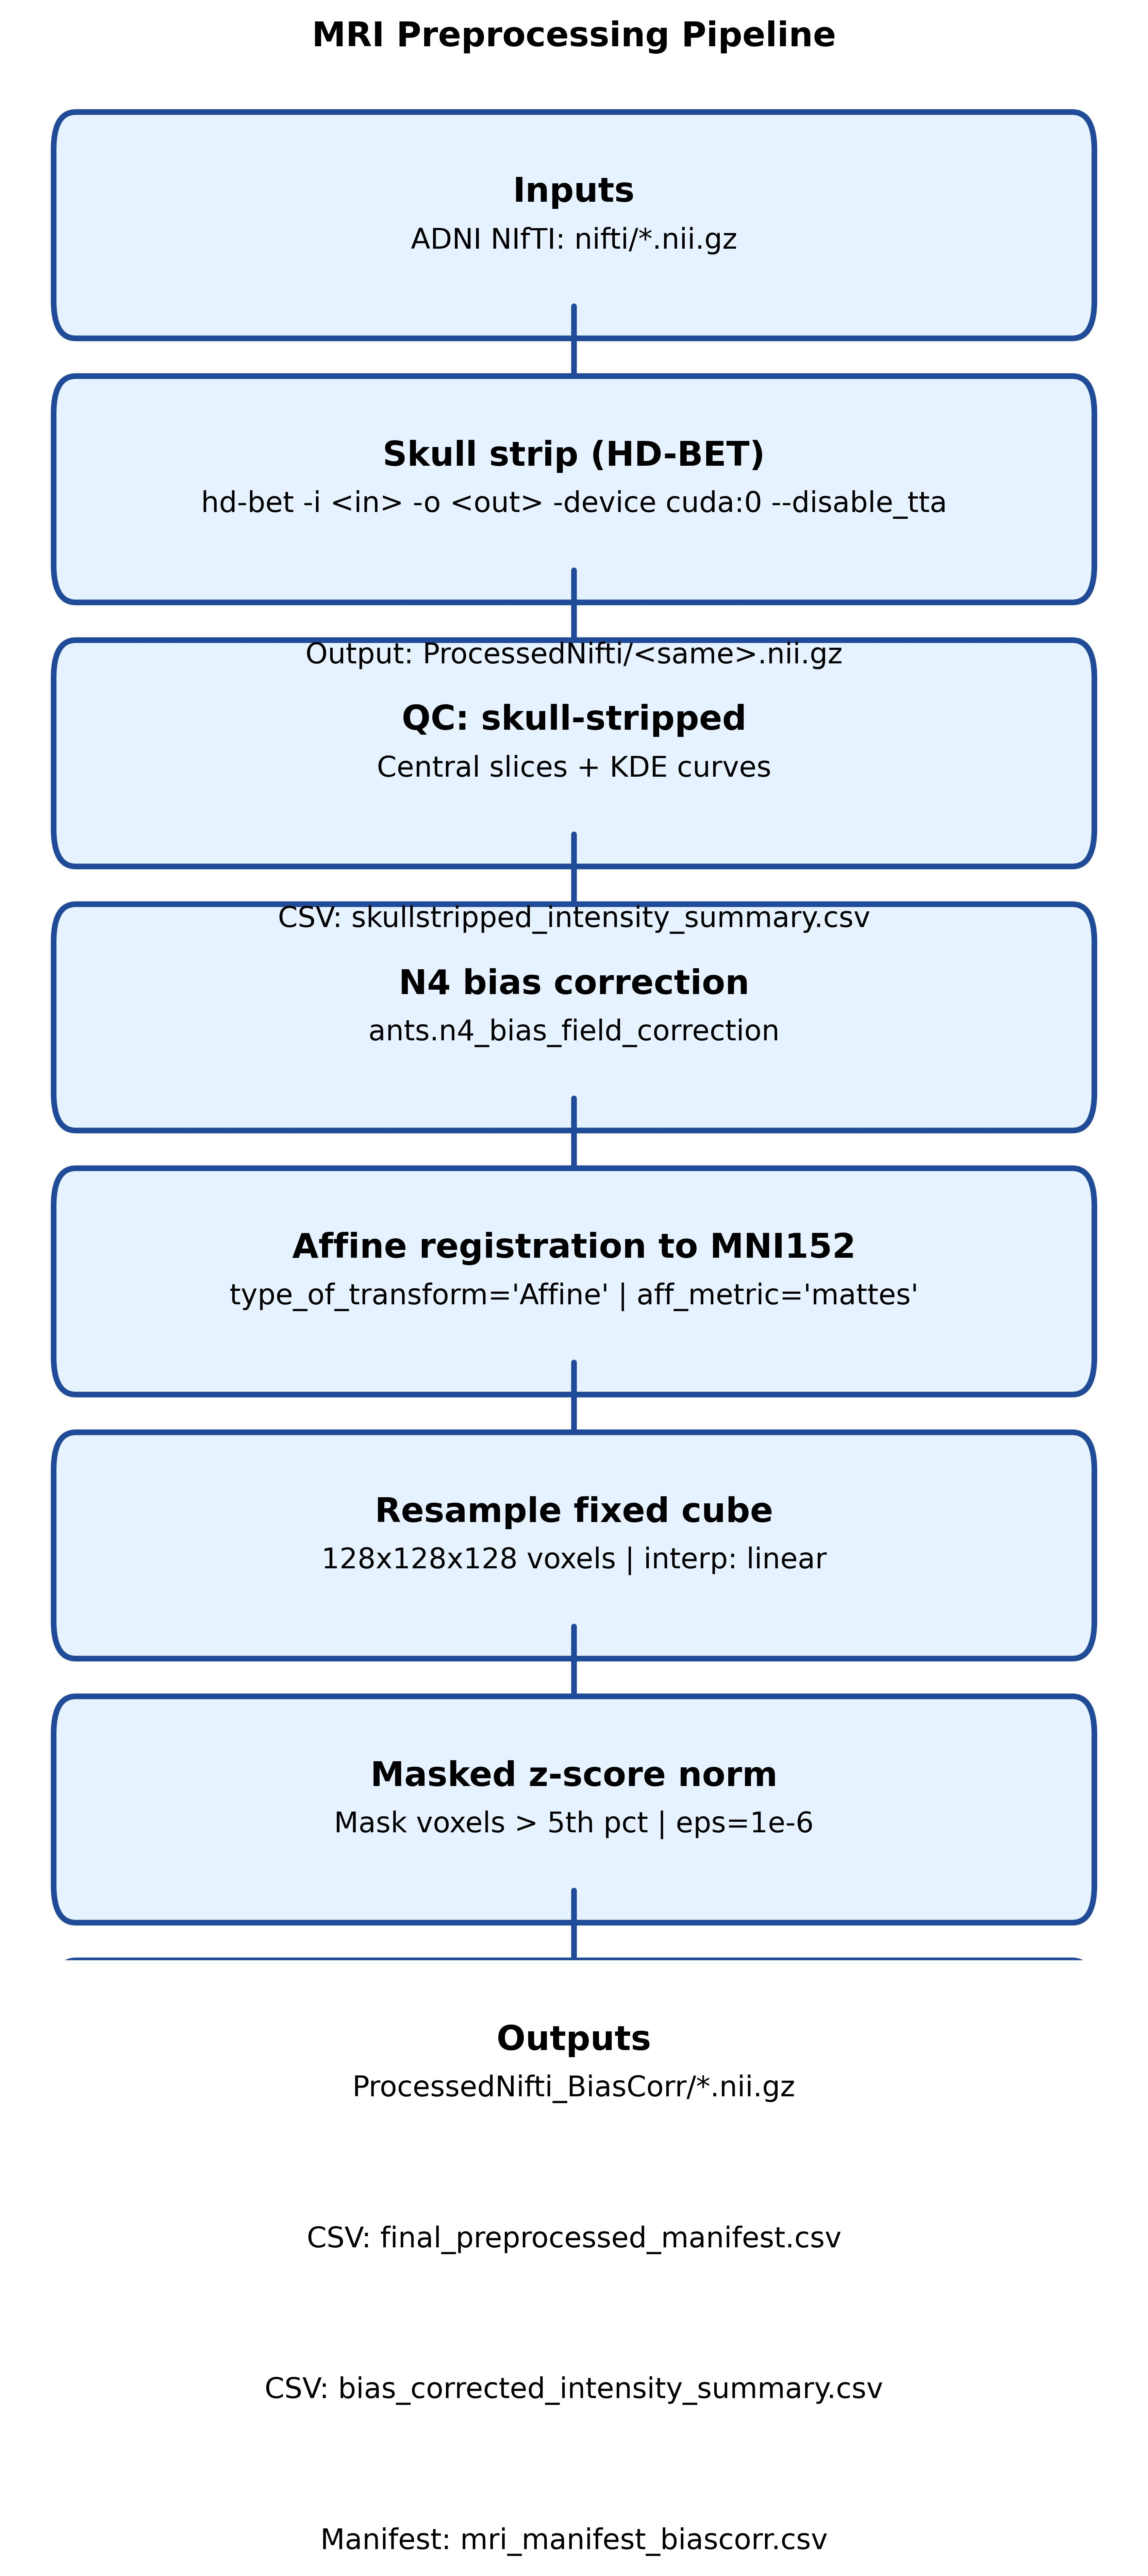

Saved pipeline diagram to plots/preprocessing_pipeline.jpg


In [20]:
from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

steps = [
    ("Inputs", ["ADNI NIfTI: nifti/*.nii.gz"]),
    ("Skull strip (HD-BET)", ["hd-bet -i <in> -o <out> -device cuda:0 --disable_tta", "Output: ProcessedNifti/<same>.nii.gz"]),
    ("QC: skull-stripped", ["Central slices + KDE curves", "CSV: skullstripped_intensity_summary.csv"]),
    ("N4 bias correction", ["ants.n4_bias_field_correction"]),
    ("Affine registration to MNI152", ["type_of_transform='Affine' | aff_metric='mattes'"]),
    ("Resample fixed cube", ["128x128x128 voxels | interp: linear"]),
    ("Masked z-score norm", ["Mask voxels > 5th pct | eps=1e-6"]),
    ("Outputs", ["ProcessedNifti_BiasCorr/*.nii.gz", "CSV: final_preprocessed_manifest.csv", "CSV: bias_corrected_intensity_summary.csv", "Manifest: mri_manifest_biascorr.csv"]),
]

fig, ax = plt.subplots(figsize=(7, 12))
ax.axis('off')

x = 0.5
start_y = 0.92
box_w = 0.9
box_h = 0.08
gap = 0.06

for idx, (title, lines) in enumerate(steps):
    cy = start_y - idx * (box_h + gap)
    ax.add_patch(FancyBboxPatch((x - box_w / 2, cy - box_h / 2), box_w, box_h,
                                boxstyle='round,pad=0.02', linewidth=2, edgecolor='#1f4b99', facecolor='#e6f2ff'))
    ax.text(x, cy + box_h * 0.22, title, ha='center', va='center', fontsize=12, fontweight='bold')
    for j, line in enumerate(lines):
        ax.text(x, cy - box_h * 0.1 - j * 0.08, line, ha='center', va='center', fontsize=10)
    if idx < len(steps) - 1:
        next_cy = start_y - (idx + 1) * (box_h + gap)
        arrow = FancyArrowPatch((x, cy - box_h / 2), (x, next_cy + box_h / 2),
                                arrowstyle='->', mutation_scale=12, linewidth=2, color='#1f4b99')
        ax.add_patch(arrow)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title('MRI Preprocessing Pipeline', fontsize=12, weight='bold', pad=10)

jpg_path = PLOTS_DIR / 'preprocessing_pipeline.jpg'
plt.savefig(jpg_path, dpi=600, bbox_inches='tight')
plt.close(fig)

display(Image(filename=str(jpg_path)))
print(f'Saved pipeline diagram to {jpg_path}')


Preprocessing

In [ ]:
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# =========================================================
# PATHS
# =========================================================
fname = "051_S_4929_I335399_std.nii.gz"

base = Path("/media/faizaan/1C4E3FB04E3F8196/1_DATA_PROJECTS/Projects/MutimodelFutureTrends")

paths = {
    "Original": base / "nifti" / fname,
    "Skull-Stripped": base / "ProcessedNifti" / fname,
    "Bias Corrected": base / "ProcessedNifti_BiasCorr" / fname,
}

# =========================================================
# HELPERS
# =========================================================
def load_norm(p):
    img = nib.load(str(p))
    data = img.get_fdata().astype(np.float32)
    data = np.nan_to_num(data)
    return (data - data.min()) / (data.max() - data.min() + 1e-8)

def get_slices(vol):
    """Correct central slices: axial=Z, coronal=Y, sagittal=X"""
    x, y, z = vol.shape
    axial    = vol[:, :, z//2]      # XY plane
    coronal  = vol[:, y//2, :]      # XZ plane
    sagittal = vol[x//2, :, :]      # YZ plane
    return axial, coronal, sagittal

# =========================================================
# FUNCTION TO PLOT ONE FIGURE (AX–CO–SA)
# =========================================================
def plot_three_views(title, path, dpi=600):
    vol = load_norm(path)
    axial, coronal, sagittal = get_slices(vol)

    fig, axs = plt.subplots(1, 3, figsize=(12, 4), dpi=dpi)

    views = [axial, coronal, sagittal]
    names = ["Axial", "Coronal", "Sagittal"]

    for i, img in enumerate(views):
        axs[i].imshow(np.rot90(img), cmap="gray")   # kept rotation for display
        axs[i].set_title(f"{title} — {names[i]}", fontsize=12)
        axs[i].axis("off")

    plt.tight_layout()
    plt.show()

# =========================================================
# GENERATE ALL 3 PLOTS
# =========================================================
plot_three_views("Original NIfTI", paths["Original"], dpi=1200)
plot_three_views("Skull-Stripped", paths["Skull-Stripped"], dpi=1200)
plot_three_views("Bias Corrected", paths["Bias Corrected"], dpi=1200)


ROC base proposed

Saved revised Figure 2 to: /media/faizaan/4TB/1_DATA_PROJECTS/Projects/Alheimers 6 class classification CBM/notebooks/plots/stratified_5fold_cv_revised.jpg


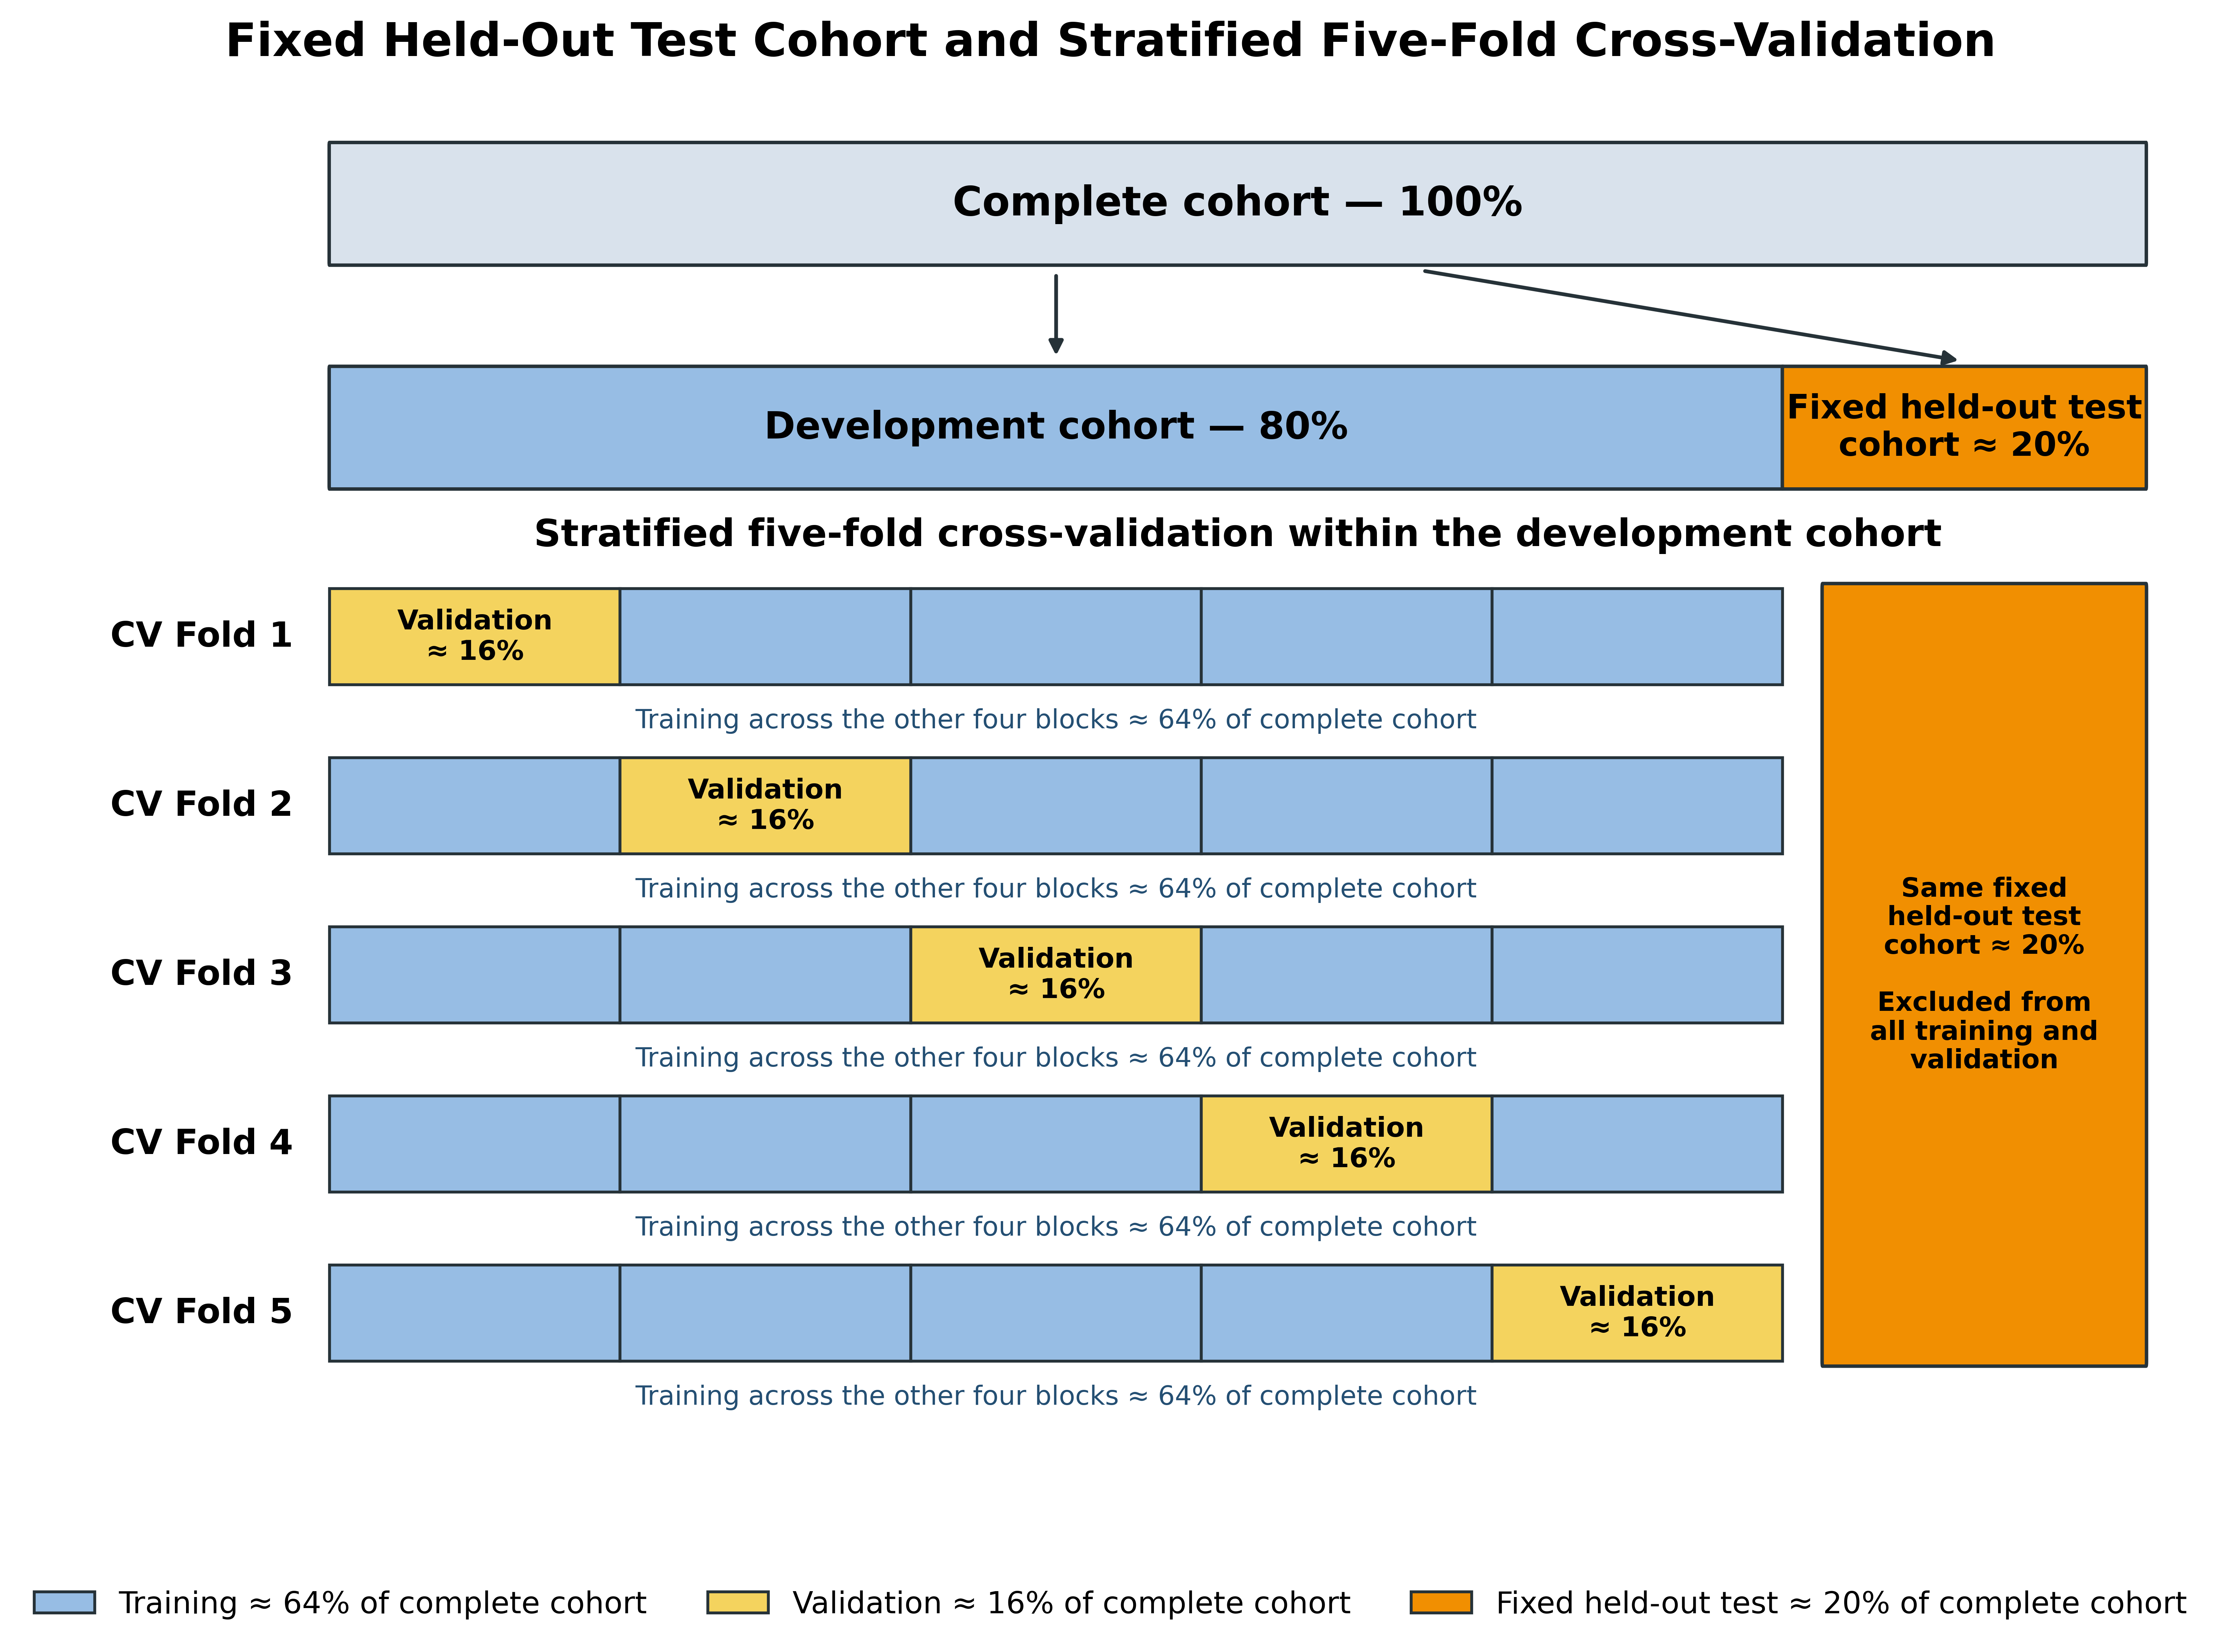

In [3]:
# Revised Figure 2: fixed held-out test cohort and stratified five-fold development split
# This is a new figure; the existing schematic and its output file are intentionally untouched.
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches

DPI = 600
TITLE_SIZE = 16
LABEL_SIZE = 12
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)
OUTPUT_PATH = PLOTS_DIR / "stratified_5fold_cv_revised.jpg"

train_color = "#97bde4"
validation_color = "#f4d35e"
test_color = "#f18f01"
cohort_color = "#d9e2ec"
edge_color = "#263238"

fig, ax = plt.subplots(figsize=(12, 8), dpi=DPI)

# Complete cohort (100%).
ax.add_patch(patches.FancyBboxPatch((0, 7.55), 100, 0.70, boxstyle="round,pad=0.02", facecolor=cohort_color, edgecolor=edge_color, linewidth=1.2))
ax.text(50, 7.90, "Complete cohort — 100%", ha="center", va="center", fontsize=14, fontweight="bold")

# Fixed split performed before any cross-validation.
ax.annotate("", xy=(40, 6.95), xytext=(40, 7.50), arrowprops=dict(arrowstyle="-|>", color=edge_color, lw=1.3))
ax.annotate("", xy=(90, 6.95), xytext=(60, 7.50), arrowprops=dict(arrowstyle="-|>", color=edge_color, lw=1.3))
ax.add_patch(patches.FancyBboxPatch((0, 6.20), 80, 0.70, boxstyle="round,pad=0.02", facecolor=train_color, edgecolor=edge_color, linewidth=1.2))
ax.add_patch(patches.FancyBboxPatch((80, 6.20), 20, 0.70, boxstyle="round,pad=0.02", facecolor=test_color, edgecolor=edge_color, linewidth=1.2))
ax.text(40, 6.55, "Development cohort — 80%", ha="center", va="center", fontsize=13, fontweight="bold")
ax.text(90, 6.55, "Fixed held-out test" + chr(10) + "cohort ≈ 20%", ha="center", va="center", fontsize=11.5, fontweight="bold")
ax.text(50, 5.90, "Stratified five-fold cross-validation within the development cohort", ha="center", va="center", fontsize=13, fontweight="bold")

# Each development fold is 16% of the complete cohort; one is validation and four total 64% training.
fold_height = 0.58
fold_gap = 1.02
first_y = 5.00
for fold_index in range(5):
    y = first_y - fold_index * fold_gap
    for block_index in range(5):
        is_validation = block_index == fold_index
        ax.add_patch(patches.Rectangle((block_index * 16, y), 16, fold_height, facecolor=validation_color if is_validation else train_color, edgecolor=edge_color, linewidth=1.0))
        if is_validation:
            ax.text(block_index * 16 + 8, y + fold_height / 2, "Validation" + chr(10) + "≈ 16%", ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(-2.0, y + fold_height / 2, f"CV Fold {fold_index + 1}", ha="right", va="center", fontsize=LABEL_SIZE, fontweight="bold")
    ax.text(40, y - 0.14, "Training across the other four blocks ≈ 64% of complete cohort", ha="center", va="top", fontsize=9.2, color="#244f73")

# The same held-out test cohort remains outside every CV iteration.
test_bottom = first_y - 4 * fold_gap
test_top = first_y + fold_height
ax.add_patch(patches.FancyBboxPatch((82.2, test_bottom), 17.8, test_top - test_bottom, boxstyle="round,pad=0.03", facecolor=test_color, edgecolor=edge_color, linewidth=1.2))
ax.text(91.1, (test_bottom + test_top) / 2, chr(10).join(["Same fixed", "held-out test", "cohort ≈ 20%", "", "Excluded from", "all training and", "validation"]), ha="center", va="center", fontsize=9.2, fontweight="bold", linespacing=1.15)

legend_handles = [
    patches.Patch(facecolor=train_color, edgecolor=edge_color, label="Training ≈ 64% of complete cohort"),
    patches.Patch(facecolor=validation_color, edgecolor=edge_color, label="Validation ≈ 16% of complete cohort"),
    patches.Patch(facecolor=test_color, edgecolor=edge_color, label="Fixed held-out test ≈ 20% of complete cohort"),
]
ax.legend(handles=legend_handles, loc="lower center", bbox_to_anchor=(0.5, -0.10), ncol=3, fontsize=10.5, frameon=False)
ax.set_xlim(-17, 103)
ax.set_ylim(0.05, 8.55)
ax.axis("off")
ax.set_title("Fixed Held-Out Test Cohort and Stratified Five-Fold Cross-Validation", fontsize=TITLE_SIZE, fontweight="bold", pad=14)
plt.tight_layout()
fig.savefig(OUTPUT_PATH, dpi=DPI, bbox_inches="tight", facecolor="white")
print(f"Saved revised Figure 2 to: {OUTPUT_PATH.resolve()}")
plt.show()
